# Sesión 3 · Separar objetos del fondo y medir qué tan bien lo hacemos
**Unidad 3. Segmentación** · Procesamiento Digital de Imágenes · Maestría en Ciencia de Datos e Información · INFOTEC · 2027-1

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/egonzalez1989/pdi-mcdi/blob/main/sesiones/S3_Segmentacion.ipynb)

**Objetivo de la sesión.** Comparar métodos de segmentación clásicos y evaluarlos con IoU y Dice.

**Clase síncrona:** jueves 25 de febrero de 2027, de 11:00 a 13:00 hrs. · **Sesiones opcionales de la unidad** (12:00 a 13:00 hrs.): jueves 11 de marzo (dudas de la actividad 3A); jueves 1 de abril (retroalimentación de 3A; evaluación oral en esta semana a quienes sean seleccionados).

**Agenda (120 min)**
1. Bordes: Sobel, Canny y Hough para contar monedas (25 min)
2. Umbral global, Otsu y adaptativo (20 min)
3. Regiones: componentes conexas y watershed (20 min)
4. Agrupamiento con k-means (15 min)
5. Evaluación con IoU y Dice; panorama U-Net/SAM (20 min)
6. Actividad 3A y dudas (20 min)

**Cómo usar este cuaderno.** Ejecuta las celdas en orden (`Shift + Enter`). Las secciones marcadas con 🧪 son pausas para que experimentes cambiando parámetros; las marcadas con 💬 son preguntas para discutir en la sesión. Al final encontrarás la conexión con la actividad **3A**.

In [1]:
# Configuración del entorno. En Google Colab todas estas bibliotecas ya vienen instaladas.
import sys, platform
import numpy as np
import matplotlib.pyplot as plt
import cv2
import skimage
from skimage import data

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10, "image.cmap": "gray"})
np.random.seed(42)

def mostrar(imagenes, titulos=None, cols=None, cmap="gray", tam=3.2, ejes=False):
    """Muestra una lista de imágenes en una cuadrícula. Las imágenes a color deben estar en RGB."""
    if not isinstance(imagenes, (list, tuple)):
        imagenes = [imagenes]
    n = len(imagenes)
    cols = cols or min(n, 4)
    filas = int(np.ceil(n / cols))
    fig, axs = plt.subplots(filas, cols, figsize=(tam * cols, tam * filas), squeeze=False)
    for i, ax in enumerate(axs.flat):
        if i < n:
            im = imagenes[i]
            ax.imshow(im, cmap=None if im.ndim == 3 else cmap)
            if titulos:
                ax.set_title(titulos[i])
        if not ejes or i >= n:
            ax.axis("off")
    plt.tight_layout()
    plt.show()

print(f"Python {platform.python_version()} | NumPy {np.__version__} | OpenCV {cv2.__version__} | scikit-image {skimage.__version__}")

import pandas as pd
from scipy import ndimage as ndi
from skimage import measure, segmentation, feature, color, filters

Python 3.12.15 | NumPy 2.5.4 | OpenCV 5.0.0 | scikit-image 0.26.0


## 1. ¿Qué es segmentar?
Particionar la imagen en regiones con significado. Dos familias clásicas:
- **Discontinuidad:** buscar cambios bruscos de intensidad → **bordes**.
- **Similaridad:** agrupar píxeles parecidos → **umbrales, regiones, agrupamiento**.

Trabajaremos con `coins` (monedas sobre fondo con iluminación variable), un caso típico de conteo y medición de objetos.

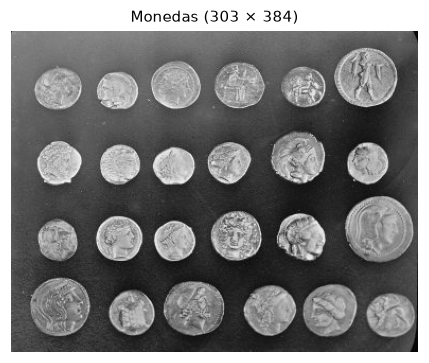

In [2]:
monedas = data.coins()
suave = cv2.GaussianBlur(monedas, (5, 5), 0)
mostrar([monedas], ["Monedas (303 × 384)"], tam=4)

## 2. Segmentación por discontinuidades
### Gradiente y Sobel
El gradiente $\nabla f = (\partial f/\partial x, \partial f/\partial y)$ apunta hacia el mayor cambio; su magnitud resalta los bordes.

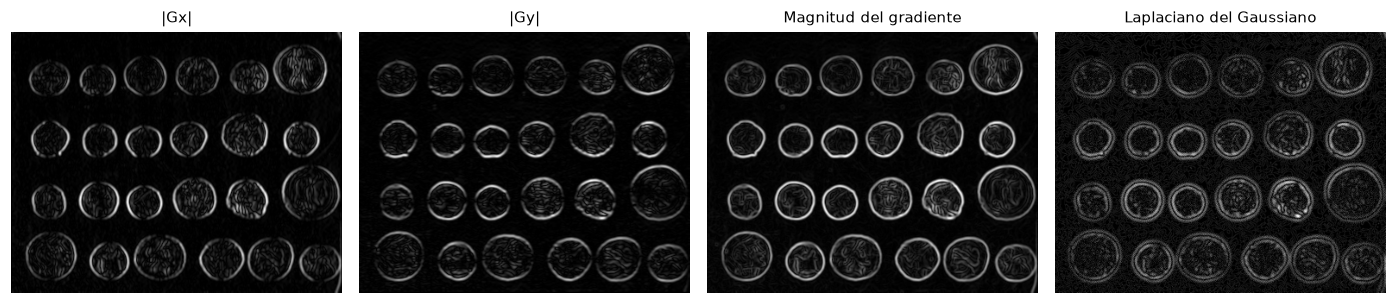

In [3]:
gx = cv2.Sobel(suave, cv2.CV_64F, 1, 0, ksize=3)
gy = cv2.Sobel(suave, cv2.CV_64F, 0, 1, ksize=3)
magnitud = np.hypot(gx, gy)
direccion = np.arctan2(gy, gx)
log = np.abs(cv2.Laplacian(cv2.GaussianBlur(monedas, (0, 0), 2), cv2.CV_64F))
mostrar([np.abs(gx), np.abs(gy), magnitud, log], ["|Gx|", "|Gy|", "Magnitud del gradiente", "Laplaciano del Gaussiano"])

### Canny: el detector de bordes de referencia
1) Suavizado gaussiano → 2) gradiente → 3) **supresión de no máximos** (bordes de 1 píxel) → 4) **histéresis** con dos umbrales: los píxeles fuertes son borde; los débiles solo si se conectan a uno fuerte.

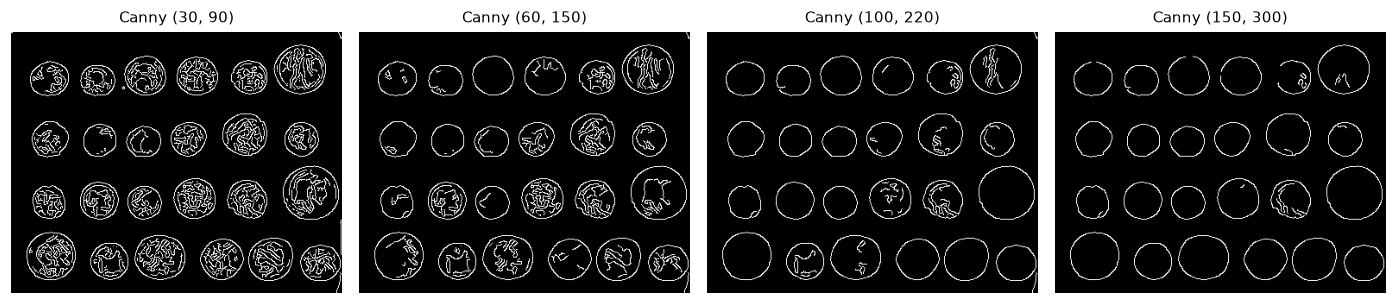

In [4]:
pares = [(30, 90), (60, 150), (100, 220), (150, 300)]
mostrar([cv2.Canny(suave, a, b) for a, b in pares], [f"Canny ({a}, {b})" for a, b in pares])

💬 Con umbrales bajos aparecen bordes de textura; con altos se pierden contornos. Una regla práctica: `alto ≈ 2–3 × bajo`, o derivarlos de la mediana de la imagen.

### Transformada de Hough: de bordes a objetos
Si sabemos que buscamos **círculos**, Hough vota en el espacio de parámetros (centro, radio) y nos da objetos, no solo bordes.

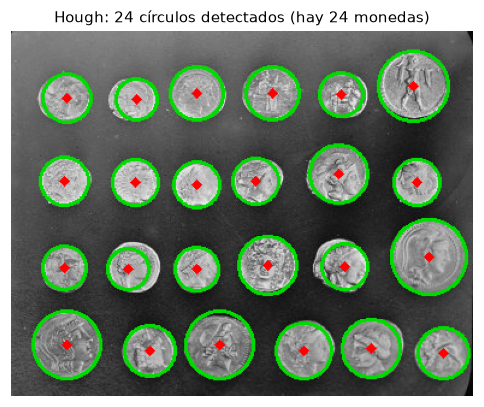

In [5]:
circulos = cv2.HoughCircles(suave, cv2.HOUGH_GRADIENT, dp=1.2, minDist=25,
                            param1=150, param2=28, minRadius=15, maxRadius=40)
salida = cv2.cvtColor(monedas, cv2.COLOR_GRAY2RGB)
if circulos is not None:
    for x, y, r in np.round(circulos[0]).astype(int):
        cv2.circle(salida, (x, y), r, (0, 220, 0), 2)
        cv2.circle(salida, (x, y), 2, (255, 0, 0), 3)
n_circ = 0 if circulos is None else len(circulos[0])
mostrar([salida], [f"Hough: {n_circ} círculos detectados (hay 24 monedas)"], tam=4.5)

## 3. Segmentación por similaridad: umbralización
- **Global:** un solo umbral $T$ para toda la imagen.
- **Otsu (1979):** elige $T$ que maximiza la varianza **entre** clases del histograma. Automático, pero supone iluminación uniforme y un histograma bimodal.
- **Adaptativa:** un umbral por vecindario (media o gaussiana local menos una constante $C$).

/tmp/ipykernel_1799824/2635624657.py:6: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.10; the parameter will become keyword-only in 3.12.
  axs[0].hist(suave.ravel(), 256, (0, 256), color="#7a7a7a"); axs[0].axvline(t_otsu, color="#c8553d", lw=2, label=f"Otsu T={t_otsu:.0f}")


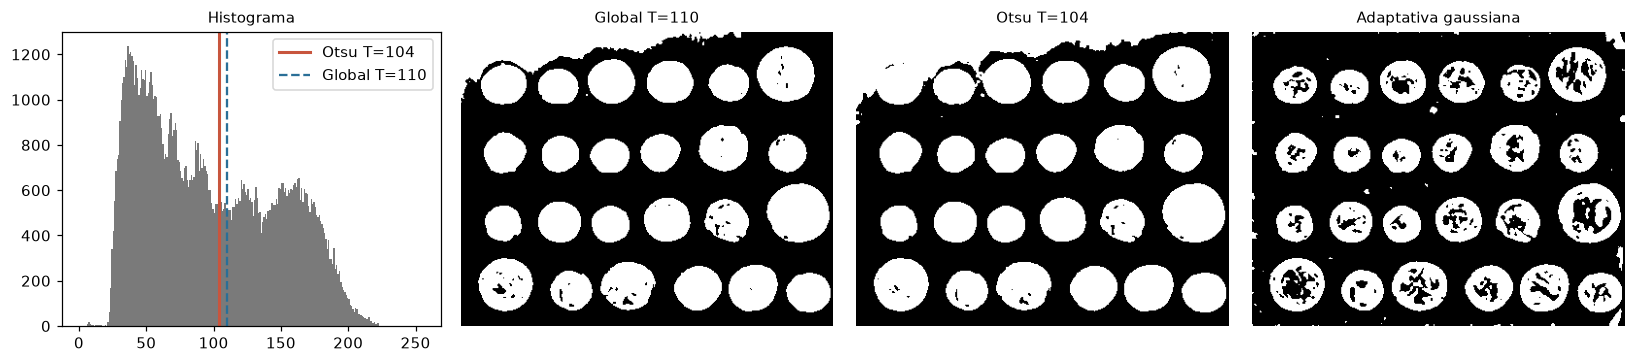

In [6]:
t_otsu, otsu = cv2.threshold(suave, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
_, global_ = cv2.threshold(suave, 110, 255, cv2.THRESH_BINARY)
adapt = cv2.adaptiveThreshold(suave, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 51, -5)

fig, axs = plt.subplots(1, 4, figsize=(15, 3.4))
axs[0].hist(suave.ravel(), 256, (0, 256), color="#7a7a7a"); axs[0].axvline(t_otsu, color="#c8553d", lw=2, label=f"Otsu T={t_otsu:.0f}")
axs[0].axvline(110, color="#2a6f97", ls="--", label="Global T=110"); axs[0].legend(); axs[0].set_title("Histograma")
for ax, im, t in zip(axs[1:], [global_, otsu, adapt], ["Global T=110", f"Otsu T={t_otsu:.0f}", "Adaptativa gaussiana"]):
    ax.imshow(im, cmap="gray"); ax.set_title(t); ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Segmentación por regiones
### Limpieza + componentes conexas = conteo y medición

Objetos detectados: 24


,label,area,eccentricity,equivalent_diameter_area
count,24.0,24.0,24.0,24.0
mean,17.2,1622.3,0.3,44.9
min,5.0,1108.0,0.2,37.6
max,29.0,3073.0,0.5,62.6


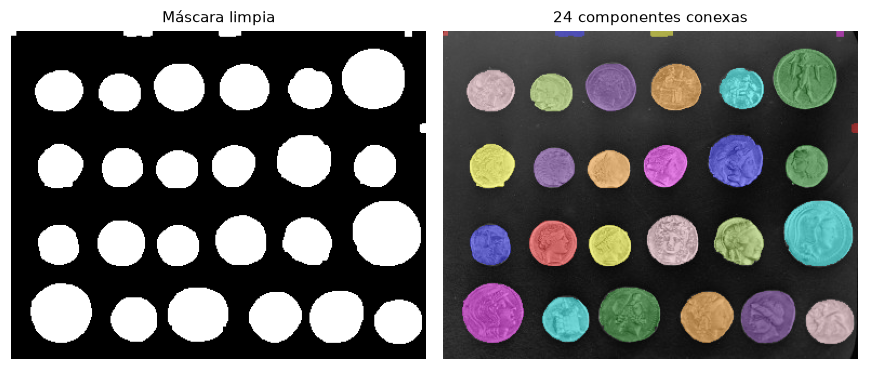

In [7]:
# Otsu local por bloques de scikit-image + morfología para rellenar las monedas
umbral_local = filters.threshold_local(suave, block_size=95, offset=-8)
mascara = suave > umbral_local
mascara = ndi.binary_fill_holes(cv2.morphologyEx(mascara.astype(np.uint8), cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8)))
mascara = cv2.morphologyEx(mascara.astype(np.uint8), cv2.MORPH_OPEN, np.ones((7, 7), np.uint8)).astype(bool)

etiquetas = measure.label(mascara)
props = measure.regionprops_table(etiquetas, properties=["label", "area", "eccentricity", "equivalent_diameter_area"])
df = pd.DataFrame(props)
df = df[df.area > 200]
print(f"Objetos detectados: {len(df)}")
display(df.describe().round(1).loc[["count", "mean", "min", "max"]])
mostrar([mascara, color.label2rgb(etiquetas, monedas, bg_label=0, alpha=0.4)],
        ["Máscara limpia", f"{len(df)} componentes conexas"], tam=4)

### Watershed: separar objetos que se tocan
Cuando dos objetos se tocan, las componentes conexas los cuentan como uno. **Watershed** trata la imagen como un relieve topográfico y "inunda" desde marcadores. Usamos la **transformada de distancia**: sus máximos locales son los centros de los objetos.

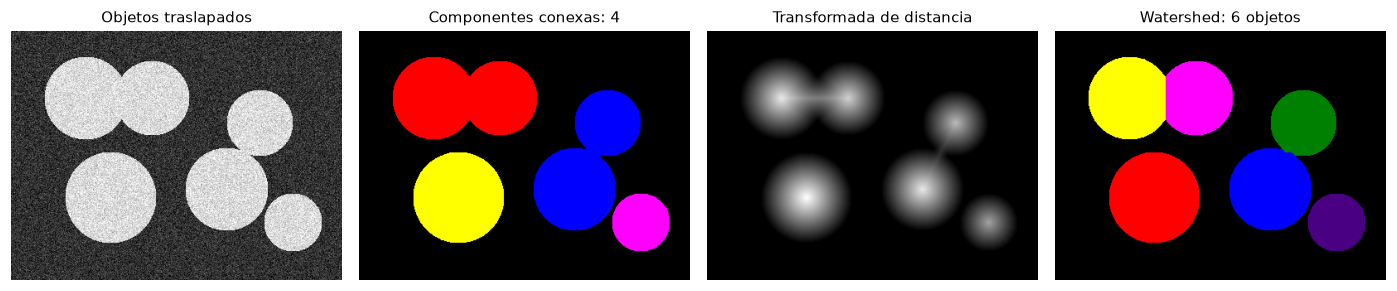

In [8]:
# Imagen sintética: círculos que se traslapan + ruido
yy, xx = np.mgrid[0:300, 0:400]
centros = [(80, 90, 50), (80, 170, 45), (200, 120, 55), (190, 260, 50), (110, 300, 40), (230, 340, 35)]
gt = np.zeros((300, 400), bool)
for cy_, cx_, r in centros:
    gt |= (yy - cy_) ** 2 + (xx - cx_) ** 2 < r ** 2
rng = np.random.default_rng(3)
sintetica = np.clip(gt * 170 + 50 + rng.normal(0, 25, gt.shape), 0, 255).astype(np.uint8)

_, bin_ = cv2.threshold(cv2.GaussianBlur(sintetica, (5, 5), 0), 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
bin_ = ndi.binary_fill_holes(bin_).astype(np.uint8)
dist = ndi.distance_transform_edt(bin_)
coords = feature.peak_local_max(dist, min_distance=25, labels=bin_)
marcadores = np.zeros_like(dist, dtype=int)
marcadores[tuple(coords.T)] = np.arange(1, len(coords) + 1)
ws = segmentation.watershed(-dist, marcadores, mask=bin_)

mostrar([sintetica, color.label2rgb(measure.label(bin_), bg_label=0), dist,
         color.label2rgb(ws, bg_label=0)],
        ["Objetos traslapados", f"Componentes conexas: {measure.label(bin_).max()}", "Transformada de distancia",
         f"Watershed: {ws.max()} objetos"])

## 5. Segmentación por agrupamiento
### k-means en el espacio de color
Cada píxel es un punto en $\mathbb{R}^3$; k-means lo asigna al centroide de color más cercano. Probamos en Lab, donde las distancias se parecen más a la percepción.

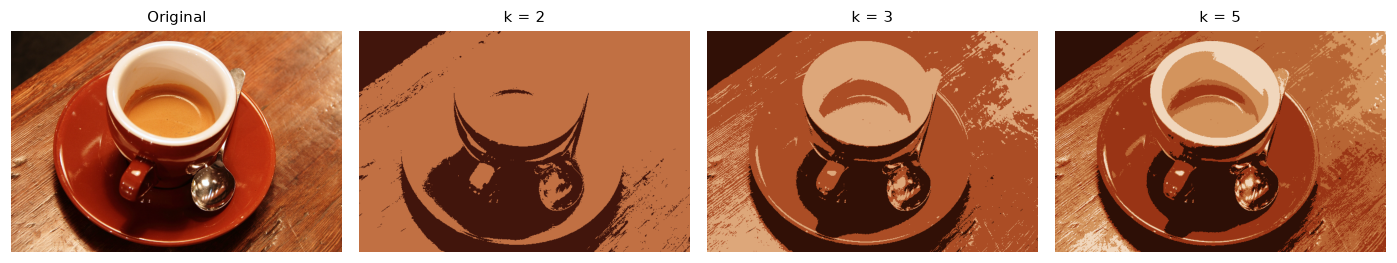

In [9]:
from sklearn.cluster import KMeans
cafe = data.coffee()
lab = cv2.cvtColor(cafe, cv2.COLOR_RGB2Lab).reshape(-1, 3).astype(np.float32)
resultados = []
for k in [2, 3, 5]:
    km = KMeans(n_clusters=k, n_init=4, random_state=0).fit(lab[::7])   # submuestreo para rapidez
    etiq = km.predict(lab).reshape(cafe.shape[:2])
    cuantizada = cv2.cvtColor(km.cluster_centers_[etiq].astype(np.uint8), cv2.COLOR_Lab2RGB)
    resultados.append(cuantizada)
mostrar([cafe] + resultados, ["Original", "k = 2", "k = 3", "k = 5"])

### Superpíxeles SLIC
Agrupan píxeles por color **y** posición en regiones compactas. Reducen cientos de miles de píxeles a cientos de regiones: muy útil como paso previo o para etiquetar datos más rápido.

n_segments=50 → 40 superpíxeles


n_segments=250 → 194 superpíxeles


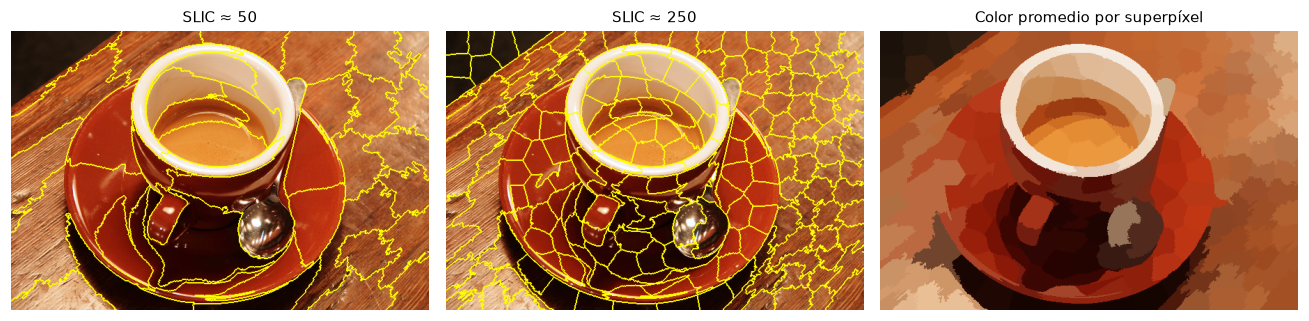

In [10]:
for n in [50, 250]:
    seg = segmentation.slic(cafe, n_segments=n, compactness=12, start_label=1)
    print(f"n_segments={n} → {seg.max()} superpíxeles")
seg = segmentation.slic(cafe, n_segments=250, compactness=12, start_label=1)
mostrar([segmentation.mark_boundaries(cafe, segmentation.slic(cafe, n_segments=50, compactness=12, start_label=1)),
         segmentation.mark_boundaries(cafe, seg), color.label2rgb(seg, cafe, kind="avg")],
        ["SLIC ≈ 50", "SLIC ≈ 250", "Color promedio por superpíxel"], tam=4)

## 6. Evaluación cuantitativa: IoU y Dice
Con una máscara de referencia $G$ y una predicción $P$:
$$\mathrm{IoU} = \frac{|P \cap G|}{|P \cup G|} \qquad \mathrm{Dice} = \frac{2|P \cap G|}{|P| + |G|}$$
Usamos la imagen sintética, de la que conocemos la verdad. Añadimos un gradiente de iluminación para hacerla realista.

,Método,IoU,Dice
4,Top-hat + Otsu,0.999,0.999
2,Adaptativa,0.936,0.967
1,Otsu,0.715,0.834
3,k-means (k=2),0.707,0.828
0,Global (T=128),0.649,0.787


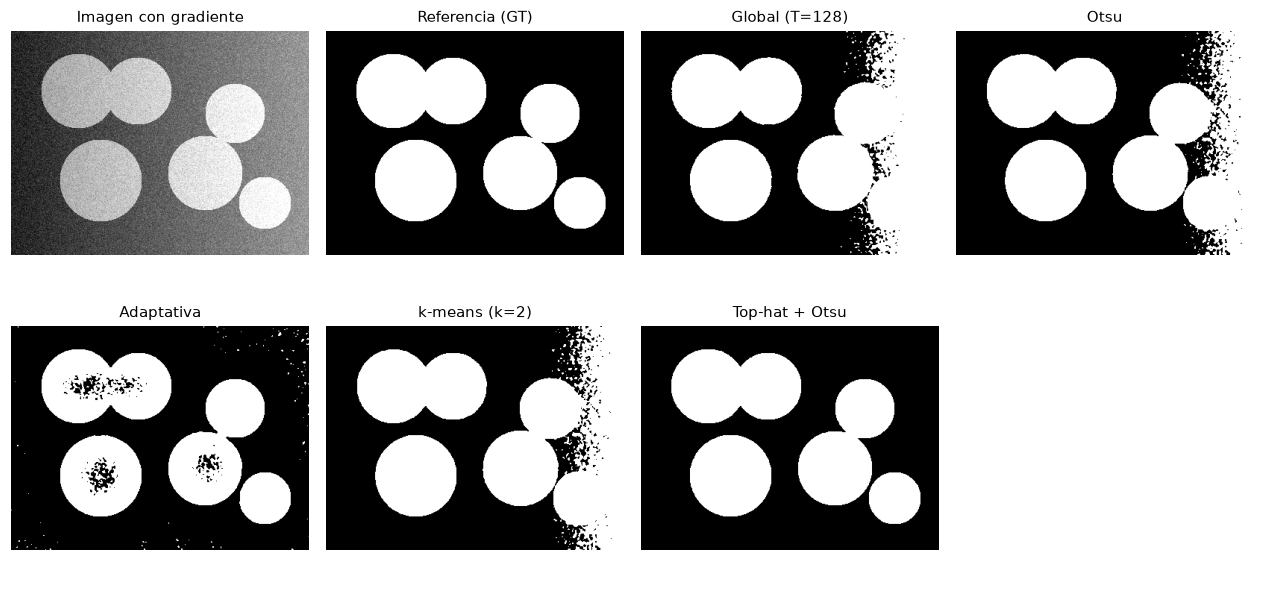

In [11]:
def iou(p, g):
    p, g = p.astype(bool), g.astype(bool)
    return (p & g).sum() / max((p | g).sum(), 1)

def dice(p, g):
    p, g = p.astype(bool), g.astype(bool)
    return 2 * (p & g).sum() / max(p.sum() + g.sum(), 1)

iluminacion = (xx / 400 * 120).astype(np.float32)
dificil = np.clip(sintetica.astype(np.float32) * 0.7 + iluminacion, 0, 255).astype(np.uint8)
d_suave = cv2.GaussianBlur(dificil, (5, 5), 0)

metodos = {}
metodos["Global (T=128)"] = d_suave > 128
_, o = cv2.threshold(d_suave, 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU); metodos["Otsu"] = o
metodos["Adaptativa"] = cv2.adaptiveThreshold(d_suave, 1, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 151, -10)
km = KMeans(2, n_init=4, random_state=0).fit(d_suave.reshape(-1, 1).astype(np.float32))
e = km.labels_.reshape(d_suave.shape); metodos["k-means (k=2)"] = e == np.argmax(km.cluster_centers_.ravel())
fondo = cv2.morphologyEx(d_suave, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (121, 121)))
_, th = cv2.threshold(cv2.subtract(d_suave, fondo), 0, 1, cv2.THRESH_BINARY + cv2.THRESH_OTSU); metodos["Top-hat + Otsu"] = th

filas = [(k, iou(v, gt), dice(v, gt)) for k, v in metodos.items()]
display(pd.DataFrame(filas, columns=["Método", "IoU", "Dice"]).sort_values("IoU", ascending=False).round(3))
mostrar([dificil, gt] + list(metodos.values()), ["Imagen con gradiente", "Referencia (GT)"] + list(metodos.keys()), cols=4, tam=2.9)

💬 **Discusión.** Otsu y k-means (k = 2) suelen dar resultados casi idénticos aquí: ¿por qué? (Pista: ambos minimizan la varianza dentro de dos grupos de intensidades.) ¿Qué ganamos al corregir la iluminación antes de umbralizar?

## 7. Panorama: segmentación con aprendizaje profundo
| Enfoque | Idea | Cuándo usarlo |
|---|---|---|
| **U-Net** (Ronneberger et al., 2015) | Codificador–decodificador con conexiones de salto; se entrena con máscaras | Tienes cientos de imágenes anotadas de tu dominio (médico, industrial) |
| **Mask R-CNN / YOLO-seg** | Segmentación de instancias | Varios objetos por imagen que hay que contar y separar |
| **Segment Anything, SAM** (Kirillov et al., 2023) | Modelo fundacional *promptable*: segmenta a partir de un punto o caja, sin reentrenar | Prototipos rápidos, **pre-etiquetado** de datos para acelerar la anotación |

La celda siguiente muestra cómo se usaría SAM en Colab con GPU (no se ejecuta por defecto: descarga ~375 MB).

In [12]:
USAR_SAM = False   # Cambia a True en Colab con GPU para probarlo
if USAR_SAM:
    # !pip install -q git+https://github.com/facebookresearch/segment-anything.git
    # !wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth
    from segment_anything import sam_model_registry, SamPredictor
    sam = sam_model_registry["vit_b"](checkpoint="sam_vit_b_01ec64.pth")
    predictor = SamPredictor(sam)
    imagen = cv2.cvtColor(monedas, cv2.COLOR_GRAY2RGB)
    predictor.set_image(imagen)
    masks, scores, _ = predictor.predict(point_coords=np.array([[60, 45]]), point_labels=np.array([1]))
    mostrar([imagen, masks[np.argmax(scores)]], ["Punto de consulta", "Máscara SAM"])
else:
    print("Ejemplo de SAM desactivado (USAR_SAM = False).")

Ejemplo de SAM desactivado (USAR_SAM = False).


## 8. Resumen y conexión con la actividad 3A
| Método | Fortaleza | Debilidad |
|---|---|---|
| Canny / Hough | Contornos precisos, objetos paramétricos | Sensible a umbrales y textura |
| Otsu | Automático | Falla con iluminación desigual |
| Adaptativa | Robusta a iluminación | Parámetros de bloque y C |
| Watershed | Separa objetos que se tocan | Sobresegmenta sin buenos marcadores |
| k-means / SLIC | Usa color; regiones compactas | Hay que elegir k |

**Actividad 3A. Segmentación de imágenes con OpenCV** (20 puntos, entrega: domingo 14 de marzo de 2027). Usa la plantilla `3A_Plantilla_Segmentacion.ipynb`: compara bordes, umbralización y k-means y **evalúa con IoU/Dice** contra la máscara de referencia (carpeta `datos/segmentacion` del repositorio).